In [5]:
import pandas as pd
from ses.pipeline import cargar_entrenamiento
from ses.models.candidates import construir_busqueda
from ses.config import ROOT
from IPython.display import Image, display
from sklearn.metrics import classification_report

In [ ]:
## Específicamente ver el rendimiento de knn con diferentes distancias (p = 1 manhattan y p = 2 euclidiana), con y sin PCA y cpn diferente número de vecinos.
X, y, cv = cargar_entrenamiento()

busqueda = construir_busqueda("knn", cv)
busqueda.fit(X, y)

print("Mejor combinación:", busqueda.best_params_)
print("Macro-F1:", round(busqueda.best_score_, 3))

# Todas las combinaciones, de mejor a peor
res = pd.DataFrame(busqueda.cv_results_)
tabla = res[["param_modelo__reduccion", "param_modelo__knn__p",
             "param_modelo__knn__n_neighbors",
             "mean_test_f1_macro", "std_test_f1_macro", "mean_test_qwk"]]
tabla.sort_values("mean_test_f1_macro", ascending=False).head(50)
# print(res)

Mejor combinación: {'modelo__knn__n_neighbors': 15, 'modelo__knn__p': 1, 'modelo__reduccion': PCA(n_components=20)}
Macro-F1: 0.549


,param_modelo__reduccion,param_modelo__knn__p,param_modelo__knn__n_neighbors,mean_test_f1_macro,std_test_f1_macro,mean_test_qwk
8,PCA(n_components=20),1,15,0.549440,0.010299,0.664537
11,PCA(n_components=20),2,15,0.548621,0.014978,0.665187
5,PCA(n_components=20),2,5,0.547602,0.008244,0.652532
2,PCA(n_components=20),1,5,0.545786,0.007732,0.652792
3,passthrough,2,5,0.545025,0.006290,0.654931
14,PCA(n_components=20),1,31,0.544147,0.009573,0.667840
7,PCA(n_components=10),1,15,0.543518,0.010859,0.661347
10,PCA(n_components=10),2,15,0.543258,0.011782,0.662164
9,passthrough,2,15,0.543018,0.008546,0.676988
17,PCA(n_components=20),2,31,0.542873,0.012609,0.668924


In [ ]:
# Comparación de todos los modelos candidatos
T = ROOT / "reports" / "tables"

resumen = pd.read_csv(T / "cv_resumen.csv")
mejores = pd.read_csv(T / "mejores_hiperparametros.csv")

resumen["valor"] = resumen["media"].map("{:.3f}".format) + " ± " + resumen["desv"].map("{:.3f}".format)
tabla = resumen.pivot(index="modelo", columns="metrica", values="valor")
tabla = tabla[["f1_macro", "qwk", "mae_ordinal", "pct_errores_lejanos", "recall_pobre", "recall_alta"]]
tabla = tabla.join(mejores.set_index("modelo")[["hiperparametros", "diferencia_con_segundo"]])
tabla.sort_values("f1_macro", ascending=False)

,f1_macro,qwk,mae_ordinal,pct_errores_lejanos,recall_pobre,recall_alta,hiperparametros,diferencia_con_segundo
modelo,,,,,,,,
lr_l1,0.596 ± 0.012,0.733 ± 0.008,0.391 ± 0.011,0.030 ± 0.003,0.722 ± 0.012,0.849 ± 0.022,{'modelo__C': 10},0.0011
lr_multinomial,0.595 ± 0.013,0.733 ± 0.009,0.392 ± 0.013,0.030 ± 0.003,0.718 ± 0.014,0.845 ± 0.025,sin grilla,NaN
lr_l2,0.595 ± 0.012,0.733 ± 0.008,0.392 ± 0.012,0.030 ± 0.003,0.723 ± 0.014,0.849 ± 0.022,{'modelo__C': 1},0.0003
pom,0.576 ± 0.010,0.733 ± 0.006,0.404 ± 0.010,0.019 ± 0.001,0.668 ± 0.014,0.826 ± 0.043,fijos,NaN
knn,0.549 ± 0.012,0.665 ± 0.015,0.389 ± 0.011,0.054 ± 0.007,0.640 ± 0.002,0.263 ± 0.039,"{'modelo__knn__n_neighbors': 15, 'modelo__knn_...",0.0008
naive_bayes,0.368 ± 0.012,0.506 ± 0.006,0.714 ± 0.020,0.108 ± 0.005,0.354 ± 0.011,0.908 ± 0.019,{'modelo__var_smoothing': 0.001},0.1647
baseline_mayoritaria,0.168 ± 0.000,0.000 ± 0.000,0.712 ± 0.000,0.216 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,fijos,NaN


              modelo  pobres  pobre_a_media_alta_n  pobre_a_media_alta_pct  media_alta  media_alta_a_pobre_n  media_alta_a_pobre_pct
baseline_mayoritaria    3402                  3402                  100.00        8625                     0                    0.00
                 pom    3402                   138                    4.06        8625                   140                    1.62
      lr_multinomial    3402                   151                    4.44        8625                   295                    3.42
               lr_l2    3402                   145                    4.26        8625                   300                    3.48
               lr_l1    3402                   148                    4.35        8625                   297                    3.44
         naive_bayes    3402                  1034                   30.39        8625                   404                    4.68
                 knn    3402                   513                   

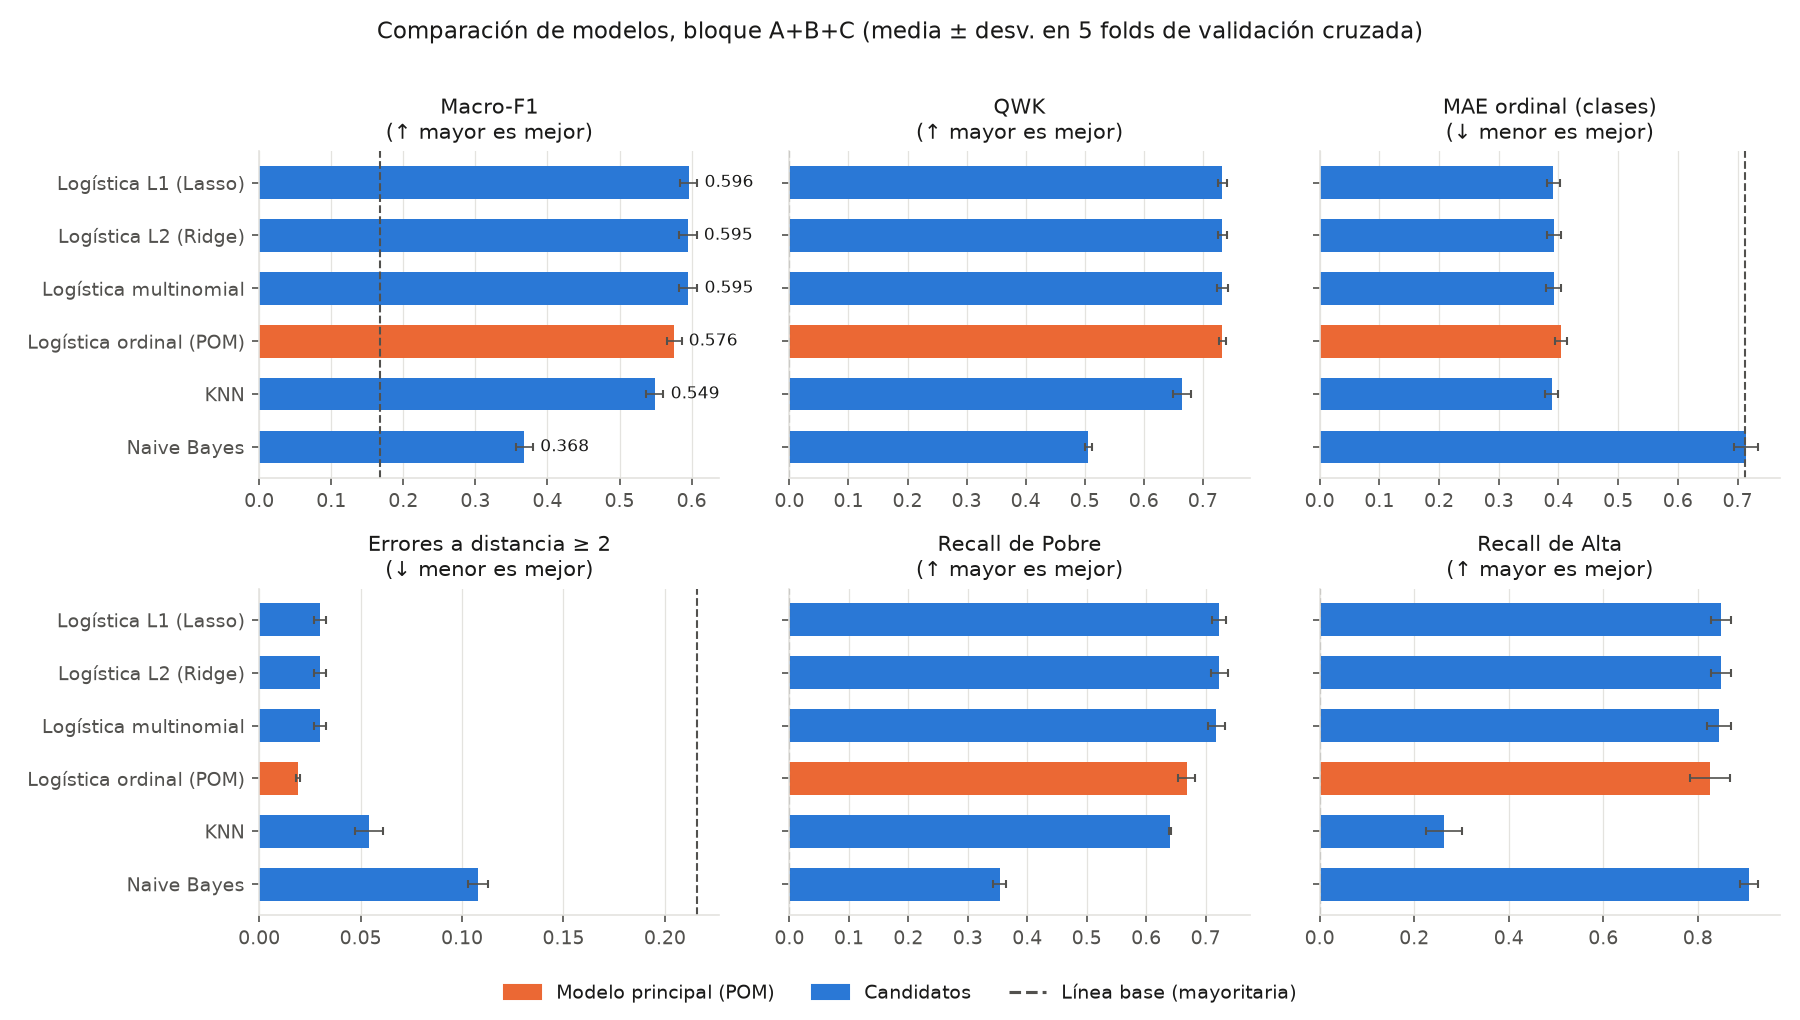

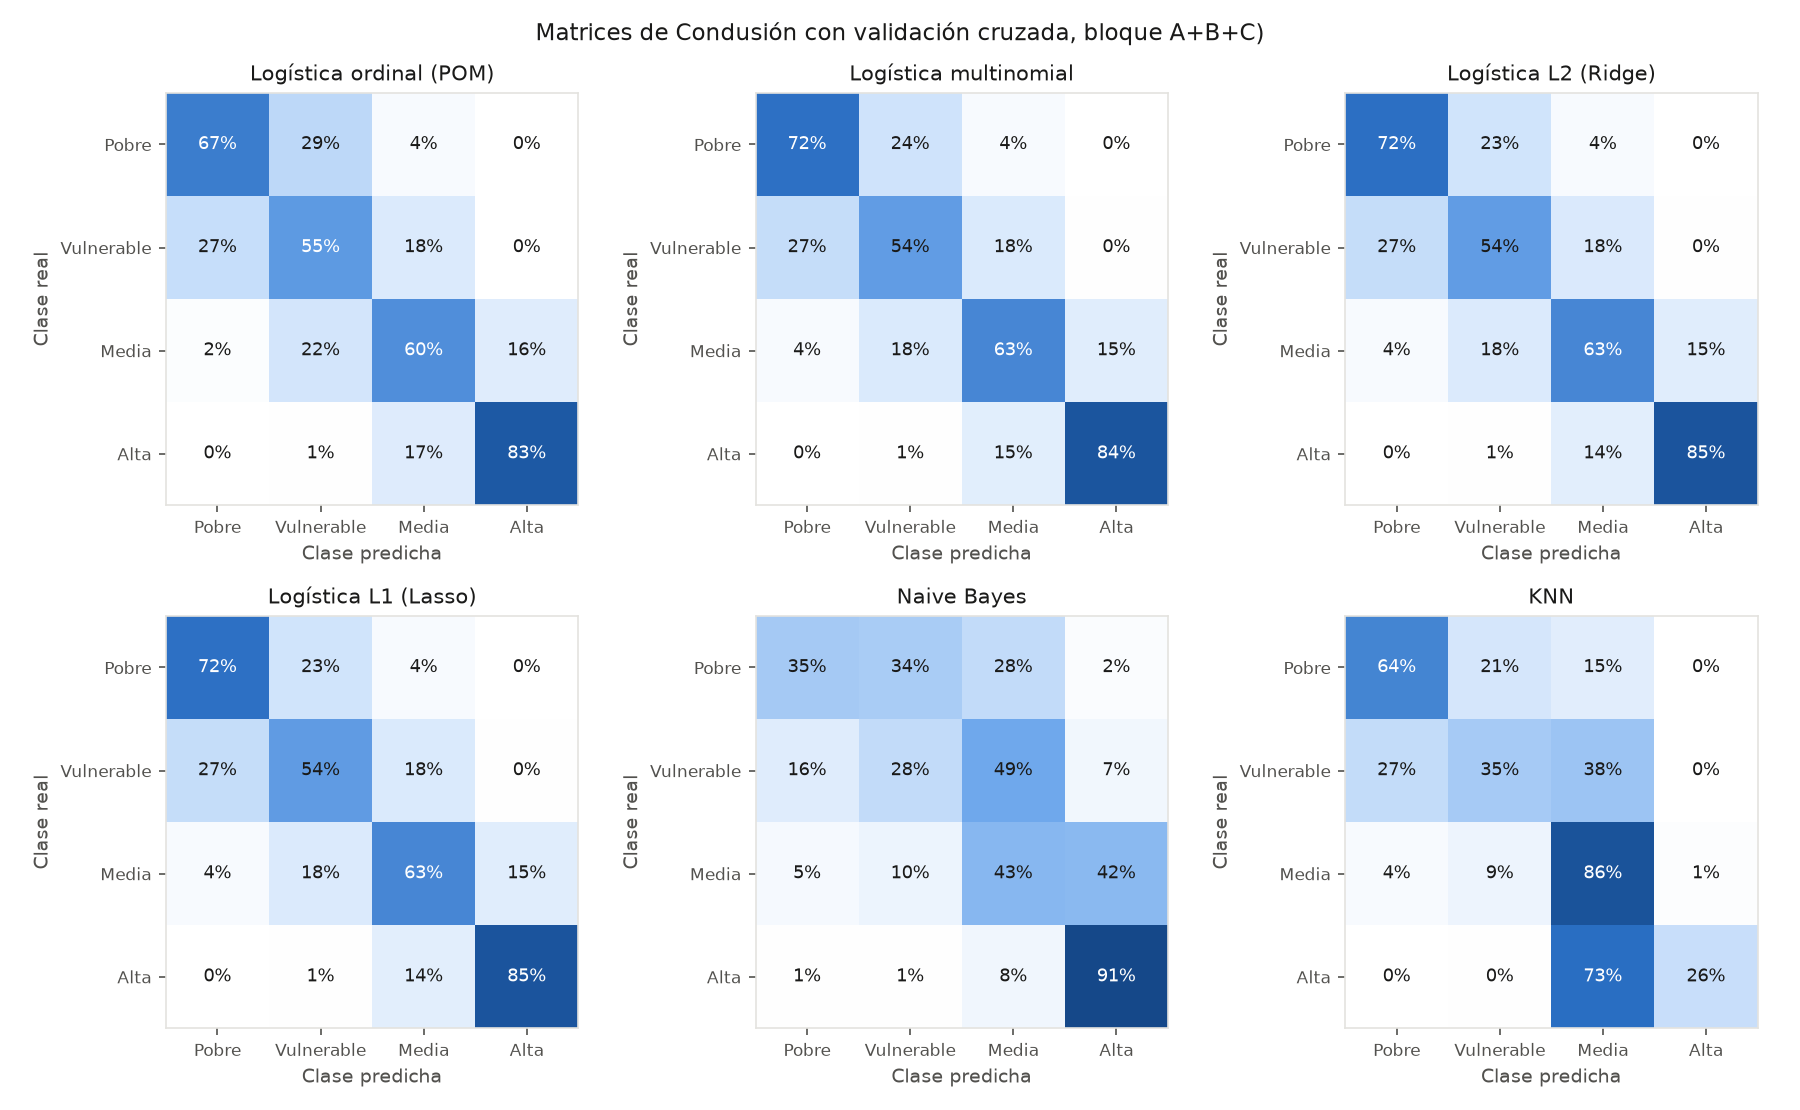

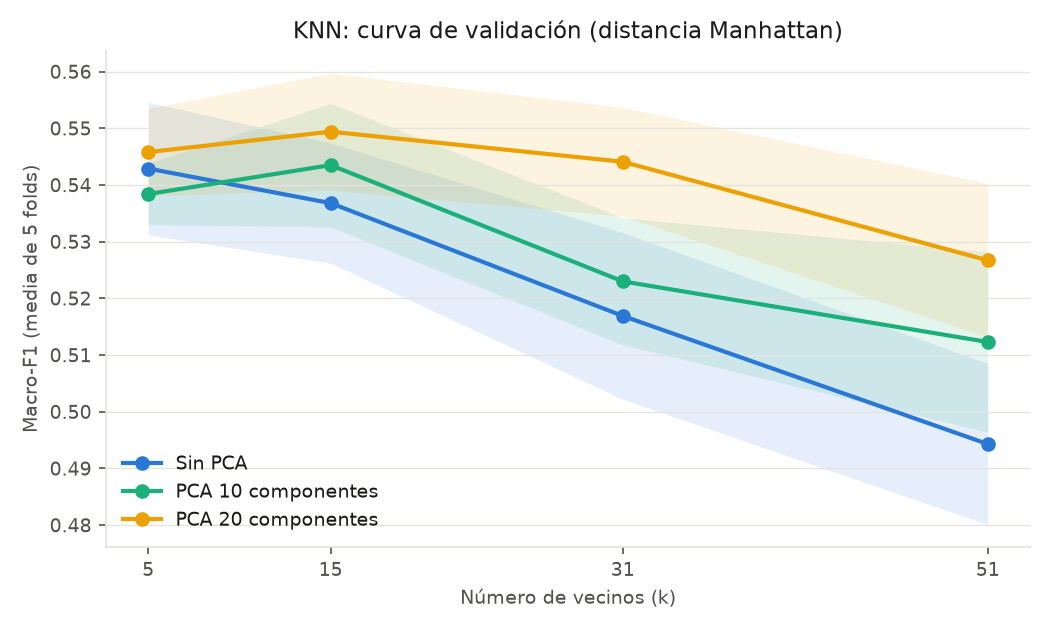

In [8]:
%run -m ses.evaluation.plots

F = ROOT / "reports" / "figures"
for nombre in ["comparacion_modelos.png", "confusion_modelos.png", "curva_knn.png"]:
    display(Image(filename=F / nombre))

In [9]:
pd.read_csv(T / "errores_pobre.csv").set_index("modelo")

,pobres,pobre_a_media_alta_n,pobre_a_media_alta_pct,media_alta,media_alta_a_pobre_n,media_alta_a_pobre_pct
modelo,,,,,,
baseline_mayoritaria,3402,3402,100.00,8625,0,0.00
pom,3402,138,4.06,8625,140,1.62
lr_multinomial,3402,151,4.44,8625,295,3.42
lr_l2,3402,145,4.26,8625,300,3.48
lr_l1,3402,148,4.35,8625,297,3.44
naive_bayes,3402,1034,30.39,8625,404,4.68
knn,3402,513,15.08,8625,325,3.77


In [10]:
pred = pd.read_csv(T / "predicciones_cv.csv")
nombres = ["Pobre", "Vulnerable", "Media", "Alta"]
for modelo in ["pom", "lr_l2", "knn"]:
    print(f"=== {modelo} ===")
    print(classification_report(pred["ses_real"], pred[modelo], target_names=nombres, digits=3))

=== pom ===
              precision    recall  f1-score   support

       Pobre      0.669     0.668     0.669      3402
  Vulnerable      0.427     0.554     0.482      3701
       Media      0.841     0.601     0.701      7929
        Alta      0.310     0.826     0.451       696

    accuracy                          0.615     15728
   macro avg      0.562     0.662     0.576     15728
weighted avg      0.683     0.615     0.632     15728

=== lr_l2 ===
              precision    recall  f1-score   support

       Pobre      0.655     0.723     0.687      3402
  Vulnerable      0.475     0.541     0.506      3701
       Media      0.845     0.629     0.721      7929
        Alta      0.320     0.849     0.465       696

    accuracy                          0.639     15728
   macro avg      0.574     0.686     0.595     15728
weighted avg      0.693     0.639     0.652     15728

=== knn ===
              precision    recall  f1-score   support

       Pobre      0.620     0.640    